# Case study: P2CRC Visium sc-SVC analysis

Analyze historical **RNA-corrected** results, not the uncorrected CRC archive.
Cell counts were estimated from transcript abundance using a fitted linear model
(`sr_cell_count_method: cyto_linear_v1`).

Use the project environment (Python 3.10.14, Scanpy 1.11.4). Set the kernel working
directory to the repository root (`%cd ../..` from `reproduce/case/`),
edit the two input paths, then **Run All**. Data are not included.

Required fields: raw `obsm["spatial"]`; reconstructed `obs["spot_name"]`
(raw spot IDs) and `obs["cell_type"]`. Outputs: inline figures and `gene_metrics`.

In [ ]:
import os

for variable in (
    "OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS", "NUMBA_NUM_THREADS", "VECLIB_MAXIMUM_THREADS",
):
    os.environ[variable] = "1"

%matplotlib inline

import math

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd
import scanpy as sc
from scipy import sparse
from scipy.sparse import csr_matrix
from scipy.spatial import cKDTree

SEED = 42

# Edit these two paths; they are relative to the repository root.
RAW_H5AD_PATH = (
    "raw_data/Real_application/cnwtb-record/spatial-cnwtb-record/h5ad/CRC/"
    "0035__GSE280313__GSM8594561_P2CRC.h5ad"
)
RECON_H5AD_PATH = (
    "raw_data/Real_application/cnwtb-record/revise-reconstruction/h5ad/CRC/"
    "0035__GSE280313__GSM8594561_P2CRC/run_tacco_rna_corrected_cyto_linear_v1/"
    "0035__GSE280313__GSM8594561_P2CRC__REVISE_sc-SVC.h5ad"
)

## Shared genes and Hallmark EMT

Use shared genes and the embedded human Hallmark EMT v2025.1 gene set.

In [ ]:
# Hallmark EMT v2025.1 (human symbols); no GMT is read by this case notebook.
EMT_GENES = (
    "ABI3BP ACTA2 ADAM12 ANPEP APLP1 AREG BASP1 BDNF BGN BMP1 CADM1 CALD1 "
    "CALU CAP2 CAPG CCN1 CCN2 CD44 CD59 CDH11 CDH2 CDH6 COL11A1 COL12A1 "
    "COL16A1 COL1A1 COL1A2 COL3A1 COL4A1 COL4A2 COL5A1 COL5A2 COL5A3 "
    "COL6A2 COL6A3 COL7A1 COL8A2 COLGALT1 COMP COPA CRLF1 CTHRC1 CXCL1 "
    "CXCL12 CXCL6 CXCL8 DAB2 DCN DKK1 DPYSL3 DST ECM1 ECM2 EDIL3 EFEMP2 "
    "ELN EMP3 ENO2 FAP FAS FBLN1 FBLN2 FBLN5 FBN1 FBN2 FERMT2 FGF2 FLNA "
    "FMOD FN1 FOXC2 FSTL1 FSTL3 FUCA1 FZD8 GADD45A GADD45B GAS1 GEM GJA1 "
    "GLIPR1 GPC1 GPX7 GREM1 HTRA1 ID2 IGFBP2 IGFBP3 IGFBP4 IL15 IL32 IL6 "
    "INHBA ITGA2 ITGA5 ITGAV ITGB1 ITGB3 ITGB5 JUN LAMA1 LAMA2 LAMA3 LAMC1 "
    "LAMC2 LGALS1 LOX LOXL1 LOXL2 LRP1 LRRC15 LUM MAGEE1 MATN2 MATN3 MCM7 "
    "MEST MFAP5 MGP MMP1 MMP14 MMP2 MMP3 MSX1 MXRA5 MYL9 MYLK NID2 NNMT "
    "NOTCH2 NT5E NTM OXTR P3H1 PCOLCE PCOLCE2 PDGFRB PDLIM4 PFN2 PLAUR "
    "PLOD1 PLOD2 PLOD3 PMEPA1 PMP22 POSTN PPIB PRRX1 PRSS2 PTHLH PTX3 PVR "
    "QSOX1 RGS4 RHOB SAT1 SCG2 SDC1 SDC4 SERPINE1 SERPINE2 SERPINH1 SFRP1 "
    "SFRP4 SGCB SGCD SGCG SLC6A8 SLIT2 SLIT3 SNAI2 SNTB1 SPARC SPOCK1 SPP1 "
    "TAGLN TFPI2 TGFB1 TGFBI TGFBR3 TGM2 THBS1 THBS2 THY1 TIMP1 TIMP3 TNC "
    "TNFAIP3 TNFRSF11B TNFRSF12A TPM1 TPM2 TPM4 VCAM1 VCAN VEGFA VEGFC VIM "
    "WIPF1 WNT5A"
).split()

GENE_BLOCK_SIZE = 256
OBSERVATION_BLOCK_SIZE = 256

raw = sc.read_h5ad(RAW_H5AD_PATH)
recon = sc.read_h5ad(RECON_H5AD_PATH)

raw_gene_names = pd.Index(raw.var_names.astype(str))
recon_gene_names = pd.Index(recon.var_names.astype(str))
recon_gene_lookup = set(recon_gene_names)
common_genes = [gene for gene in raw_gene_names if gene in recon_gene_lookup]
if not common_genes:
    raise ValueError("Raw and reconstructed H5AD files have no common genes")
raw_gene_indices = raw_gene_names.get_indexer(common_genes)
recon_gene_indices = recon_gene_names.get_indexer(common_genes)
common_gene_lookup = set(common_genes)
emt_genes = [gene for gene in EMT_GENES if gene in common_gene_lookup]
emt_indices = np.asarray([common_genes.index(gene) for gene in emt_genes], dtype=np.int64)

raw_spot_names = pd.Index(raw.obs_names.astype(str))

## Virtual-cell type map

Sunflower offsets around parent spots are display coordinates, not measured cell locations.

In [ ]:
def sunflower_offsets(n_cells, radius, phase):
    if n_cells == 1:
        return np.zeros((1, 2), dtype=np.float64)
    index = np.arange(n_cells, dtype=np.float64)
    golden_angle = math.pi * (3.0 - math.sqrt(5.0))
    offsets = np.column_stack(
        (
            np.sqrt((index + 0.5) / n_cells) * np.cos(phase + index * golden_angle),
            np.sqrt((index + 0.5) / n_cells) * np.sin(phase + index * golden_angle),
        )
    )
    offsets -= offsets.mean(axis=0, keepdims=True)
    maximum = np.linalg.norm(offsets, axis=1).max()
    return offsets if maximum == 0 else offsets * (radius / maximum)


def make_virtual_cell_coordinates(raw_adata, recon_adata):
    raw_coordinates = np.asarray(raw_adata.obsm["spatial"], dtype=np.float64)
    if raw_adata.n_obs > 1:
        nearest_distances = cKDTree(raw_coordinates).query(
            raw_coordinates, k=2
        )[0][:, 1]
        radius = 0.27 * float(np.median(nearest_distances))
    else:
        radius = 0.0
    coordinates = np.empty((recon_adata.n_obs, 2), dtype=np.float64)
    spot_names = recon_adata.obs["spot_name"].astype(str).to_numpy()
    groups = pd.Series(np.arange(recon_adata.n_obs), index=spot_names).groupby(
        level=0, sort=False
    )
    for spot_name, cell_positions in groups:
        cell_positions = cell_positions.to_numpy(dtype=np.int64)
        raw_position = raw_spot_names.get_loc(spot_name)
        phase = 2.0 * math.pi * (int(raw_position) % 1024) / 1024.0
        coordinates[cell_positions] = raw_coordinates[raw_position] + sunflower_offsets(
            len(cell_positions), radius, phase
        )
    return raw_coordinates, coordinates


def format_spatial_axis(axis, title):
    axis.set_title(title, fontsize=14, pad=10)
    axis.set_xlabel("spatial x")
    axis.set_ylabel("spatial y")
    axis.set_aspect("equal", adjustable="box")
    axis.grid(False)

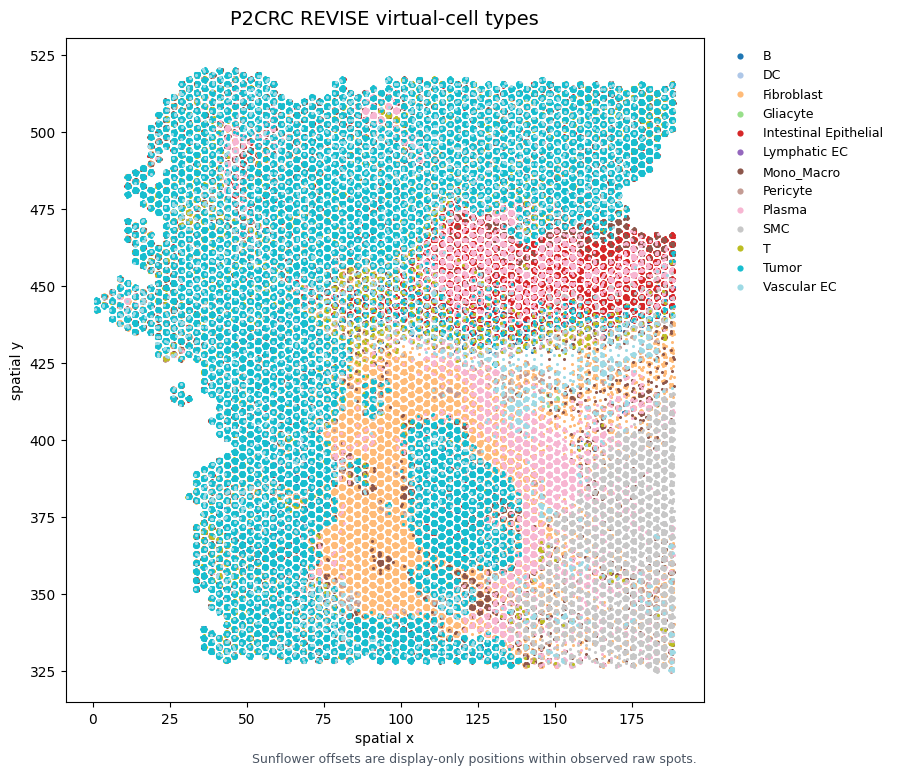

In [ ]:
raw_coordinates, cell_coordinates = make_virtual_cell_coordinates(raw, recon)
cell_types = recon.obs["cell_type"].astype(str).to_numpy()

# 1. Cell-type virtual/display spatial map.
with plt.style.context("default"):
    fig, axis = plt.subplots(figsize=(12, 8), facecolor="white")
    categories = sorted(pd.unique(cell_types))
    palette = plt.get_cmap("tab20")(np.linspace(0, 1, len(categories)))
    for category, color in zip(categories, palette):
        selected = cell_types == category
        axis.scatter(
            cell_coordinates[selected, 0], cell_coordinates[selected, 1],
            s=5, color=color, label=category, linewidths=0, rasterized=True
        )
    format_spatial_axis(axis, "P2CRC REVISE virtual-cell types")
    axis.legend(
        bbox_to_anchor=(1.02, 1), loc="upper left",
        frameon=False, fontsize=9, markerscale=2
    )
    fig.text(
        0.5, 0.015,
        "Sunflower offsets are display-only positions within observed raw spots.",
        ha="center", fontsize=9, color="#4b5563"
    )
    fig.subplots_adjust(left=0.07, right=0.78, bottom=0.09, top=0.92)
    plt.show()
    plt.close(fig)

## Hallmark EMT spatial scores

Apply CP10K + log1p on shared genes. Use a shared top-K rank-area score
(K: smaller 1st percentile of detected genes) and a common color scale.

In [ ]:
def counts_block(adata, row_start, row_end, gene_indices):
    matrix = adata.X[row_start:row_end, gene_indices]
    if sparse.issparse(matrix):
        matrix = matrix.toarray()
    return np.array(matrix, dtype=np.float32, copy=True)


def observation_totals(adata, gene_indices):
    matrix = adata.X[:, gene_indices]
    if sparse.issparse(matrix):
        values = np.asarray(matrix.sum(axis=1)).ravel()
    else:
        values = np.asarray(matrix).sum(axis=1)
    return np.asarray(values, dtype=np.float32)


def detected_gene_counts(adata, gene_indices):
    matrix = adata.X[:, gene_indices]
    if sparse.issparse(matrix):
        values = matrix.getnnz(axis=1)
    else:
        values = np.count_nonzero(np.asarray(matrix), axis=1)
    return np.asarray(values, dtype=np.float64)


def cp10k_log1p_from_counts(counts, totals):
    matrix = np.asarray(counts, dtype=np.float32)
    scale = np.divide(
        np.float32(10000.0),
        totals,
        out=np.zeros_like(totals, dtype=np.float32),
        where=totals > 0,
    )
    matrix *= scale[:, None]
    np.log1p(matrix, out=matrix)
    return matrix


def cp10k_log1p_block(adata, row_start, row_end, gene_indices, totals):
    return cp10k_log1p_from_counts(
        counts_block(adata, row_start, row_end, gene_indices),
        totals[row_start:row_end],
    )


def spatial_emt_scores(
    adata, gene_indices, target_indices, totals, cutoff_k, row_block_size
):
    """Top-K AUCell-like rank area with one shared K for the spatial panels."""
    n_observations = adata.n_obs
    n_genes = len(gene_indices)
    n_targets = len(target_indices)
    if n_targets == 0:
        raise ValueError("No shared Hallmark EMT genes")
    k = min(int(cutoff_k), n_genes)
    full_scores = np.zeros(n_observations, dtype=np.float32)
    target_lookup = np.full(n_genes, -1, dtype=np.int32)
    target_lookup[target_indices] = np.arange(n_targets, dtype=np.int32)

    for row_start in range(0, n_observations, row_block_size):
        row_end = min(row_start + row_block_size, n_observations)
        expression = cp10k_log1p_block(
            adata, row_start, row_end, gene_indices, totals
        )
        top_indices = np.argpartition(
            expression, n_genes - k, axis=1
        )[:, -k:]
        top_values = np.take_along_axis(expression, top_indices, axis=1)
        order = np.argsort(-top_values, axis=1, kind="stable")
        top_indices = np.take_along_axis(top_indices, order, axis=1)

        target_positions = target_lookup[top_indices]
        target_contribution = np.zeros(
            (row_end - row_start, n_targets), dtype=np.float32
        )
        hit_rows, hit_ranks = np.nonzero(target_positions >= 0)
        hit_targets = target_positions[hit_rows, hit_ranks]
        target_contribution[hit_rows, hit_targets] = (
            k - hit_ranks
        ).astype(np.float32)
        full_scores[row_start:row_end] = (
            target_contribution.sum(axis=1) / np.float32(k * n_targets)
        )

    return full_scores

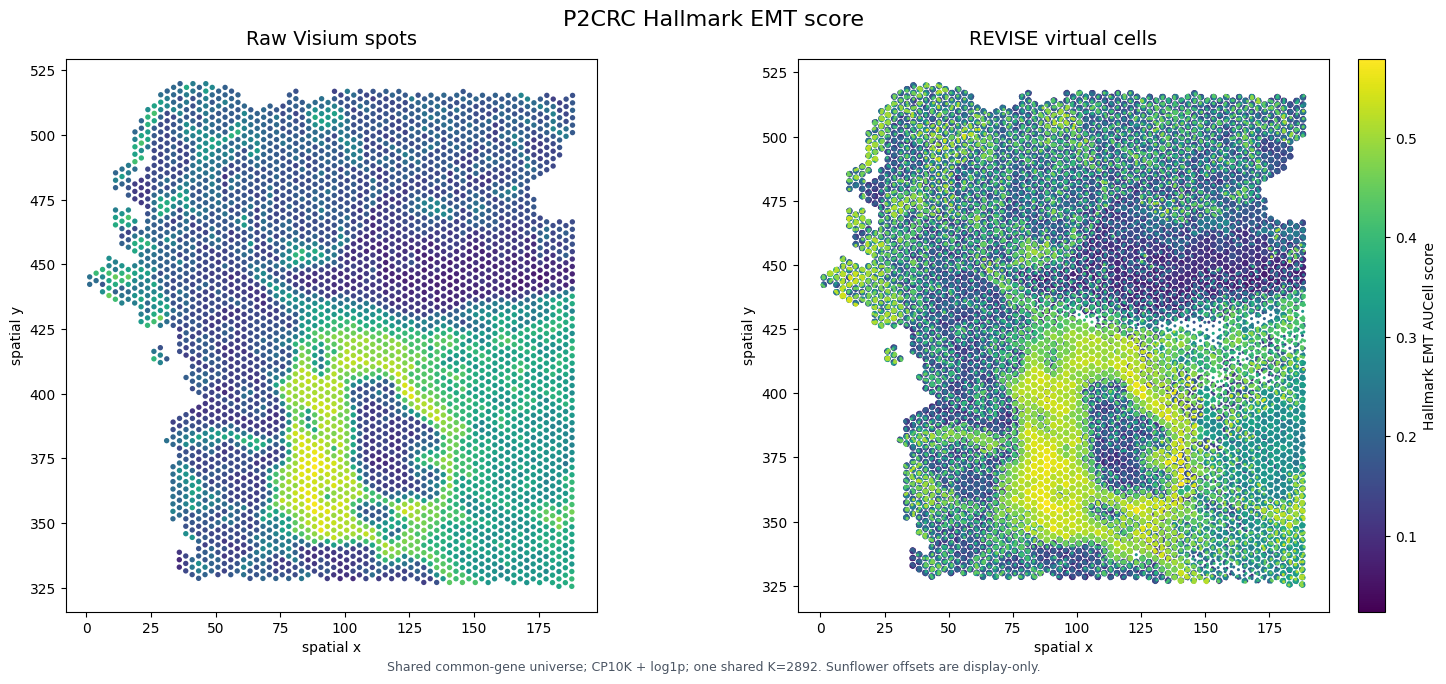

In [ ]:
raw_totals = observation_totals(raw, raw_gene_indices)
recon_totals = observation_totals(recon, recon_gene_indices)
raw_detected_q01 = float(
    np.quantile(detected_gene_counts(raw, raw_gene_indices), 0.01)
)
recon_detected_q01 = float(
    np.quantile(detected_gene_counts(recon, recon_gene_indices), 0.01)
)
AUCell_K = max(
    1,
    min(
        len(common_genes),
        int(np.floor(min(raw_detected_q01, recon_detected_q01))),
    ),
)

raw_scores = spatial_emt_scores(
    raw, raw_gene_indices, emt_indices, raw_totals,
    AUCell_K, OBSERVATION_BLOCK_SIZE
)
recon_scores = spatial_emt_scores(
    recon, recon_gene_indices, emt_indices, recon_totals,
    AUCell_K, OBSERVATION_BLOCK_SIZE
)

score_min = float(min(raw_scores.min(), recon_scores.min()))
score_max = float(max(raw_scores.max(), recon_scores.max()))
if score_max <= score_min:
    score_max = score_min + 1.0
score_norm = Normalize(vmin=score_min, vmax=score_max)

# 2. Shared-scale raw spots versus reconstructed virtual cells EMT AUCell map.
raw_order = np.argsort(raw_scores, kind="stable")
cell_order = np.argsort(recon_scores, kind="stable")
with plt.style.context("default"):
    fig, axes = plt.subplots(1, 2, figsize=(17, 7), facecolor="white")
    axes[0].scatter(
        raw_coordinates[raw_order, 0], raw_coordinates[raw_order, 1],
        c=raw_scores[raw_order], s=15, cmap="viridis", norm=score_norm,
        linewidths=0, rasterized=True
    )
    axes[1].scatter(
        cell_coordinates[cell_order, 0], cell_coordinates[cell_order, 1],
        c=recon_scores[cell_order], s=5, cmap="viridis", norm=score_norm,
        linewidths=0, rasterized=True
    )
    format_spatial_axis(axes[0], "Raw Visium spots")
    format_spatial_axis(axes[1], "REVISE virtual cells")
    fig.subplots_adjust(left=0.06, right=0.9, bottom=0.11, top=0.9, wspace=0.16)
    colorbar = fig.colorbar(
        plt.cm.ScalarMappable(norm=score_norm, cmap="viridis"),
        ax=axes.tolist(), fraction=0.025, pad=0.02
    )
    colorbar.set_label("Hallmark EMT AUCell score")
    fig.suptitle("P2CRC Hallmark EMT score", fontsize=16, y=0.97)
    fig.text(
        0.5, 0.025,
        f"Shared common-gene universe; CP10K + log1p; one shared K={AUCell_K}. "
        "Sunflower offsets are display-only.",
        ha="center", fontsize=9, color="#4b5563"
    )
    plt.show()
    plt.close(fig)

## Gene-level spatial change and EMT correlation

Compute Moran's I on separate symmetric binary 6-NN graphs using stored `.X`,
and Pearson correlation with the virtual-cell EMT rank score (seed 42).
No extra normalization or spot aggregation is applied.

Descriptive only: the virtual-cell graph uses display coordinates, and EMT genes
contribute to their own correlation score (not leave-one-out validation).

In [ ]:
def scatter_knn_graph(coordinates, k=6):
    neighbors = cKDTree(coordinates).query(coordinates, k=k + 1)[1][:, 1:]
    rows = np.repeat(np.arange(len(coordinates)), k)
    columns = neighbors.reshape(-1)
    graph = csr_matrix(
        (np.ones(len(rows), dtype=np.float64), (rows, columns)),
        shape=(len(coordinates), len(coordinates)),
    )
    graph = graph.maximum(graph.T)
    graph.setdiag(0)
    graph.eliminate_zeros()
    graph.data[:] = 1.0
    return graph


def scatter_moran_by_gene(expression, graph):
    centered = expression - expression.mean(axis=0, keepdims=True)
    denominator = np.sum(centered * centered, axis=0)
    numerator = np.sum(centered * (graph @ centered), axis=0)
    values = expression.shape[0] / float(graph.sum()) * numerator / denominator
    values[denominator == 0] = np.nan
    return values


def scatter_pearson_by_gene(expression, score):
    centered_expression = expression - expression.mean(axis=0, keepdims=True)
    centered_score = score - score.mean()
    denominator = np.sqrt(
        np.sum(centered_expression * centered_expression, axis=0)
        * np.sum(centered_score * centered_score)
    )
    values = np.sum(
        centered_expression * centered_score[:, None], axis=0
    ) / denominator
    values[denominator == 0] = np.nan
    return values


def scatter_aucell_scores(
    adata, gene_indices, target_indices, seed=42, row_block_size=256
):
    n_observations = adata.n_obs
    n_genes = len(gene_indices)
    nonzero_counts = detected_gene_counts(adata, gene_indices)
    rank_cutoff = int(round(pd.Series(nonzero_counts).quantile(0.01))) - 1
    max_auc = float((rank_cutoff + 1) * len(target_indices))

    rng = np.random.default_rng(seed)
    shuffle_order = rng.permutation(n_genes)
    inverse_shuffle = np.empty(n_genes, dtype=np.int64)
    inverse_shuffle[shuffle_order] = np.arange(n_genes, dtype=np.int64)
    target_positions = inverse_shuffle[np.asarray(target_indices, dtype=np.int64)]
    tie_order = np.arange(n_genes, dtype=np.int64)
    rank_values = np.empty(n_genes, dtype=np.int32)
    scores = np.empty(n_observations, dtype=np.float64)

    for row_start in range(0, n_observations, row_block_size):
        row_end = min(row_start + row_block_size, n_observations)
        matrix = counts_block(adata, row_start, row_end, gene_indices)
        for local_position in range(row_end - row_start):
            row = matrix[local_position, shuffle_order]
            sort_indices = np.lexsort((tie_order, -row))
            rank_values[sort_indices] = tie_order
            target_ranks = rank_values[target_positions]
            selected = np.sort(target_ranks[target_ranks < rank_cutoff])
            if selected.size == 0:
                scores[row_start + local_position] = 0.0
            else:
                x_values = np.concatenate(
                    (selected, np.asarray([rank_cutoff]))
                )
                weights = np.arange(1, selected.size + 1, dtype=np.float64)
                scores[row_start + local_position] = (
                    np.sum(np.diff(x_values) * weights) / max_auc
                )
        del matrix
    return scores, rank_cutoff

In [ ]:
emt_lookup = np.full(len(common_genes), -1, dtype=np.int32)
emt_lookup[emt_indices] = np.arange(len(emt_indices), dtype=np.int32)

scatter_raw_graph = scatter_knn_graph(raw_coordinates, k=6)
scatter_recon_graph = scatter_knn_graph(cell_coordinates, k=6)
scatter_recon_scores, scatter_rank_cutoff = scatter_aucell_scores(
    recon,
    recon_gene_indices,
    emt_indices,
    seed=SEED,
    row_block_size=OBSERVATION_BLOCK_SIZE,
)

moran_raw = np.empty(len(common_genes), dtype=np.float64)
moran_revise = np.empty(len(common_genes), dtype=np.float64)
correlation_revise = np.empty(len(common_genes), dtype=np.float64)

for gene_start in range(0, len(common_genes), GENE_BLOCK_SIZE):
    gene_end = min(gene_start + GENE_BLOCK_SIZE, len(common_genes))
    common_positions = np.arange(gene_start, gene_end, dtype=np.int64)
    raw_expression = counts_block(
        raw, 0, raw.n_obs, raw_gene_indices[common_positions]
    )
    recon_expression = counts_block(
        recon, 0, recon.n_obs, recon_gene_indices[common_positions]
    )

    moran_raw[gene_start:gene_end] = scatter_moran_by_gene(
        raw_expression, scatter_raw_graph
    )
    moran_revise[gene_start:gene_end] = scatter_moran_by_gene(
        recon_expression, scatter_recon_graph
    )
    correlation_revise[gene_start:gene_end] = scatter_pearson_by_gene(
        recon_expression, scatter_recon_scores
    )
    del raw_expression, recon_expression

gene_metrics = pd.DataFrame(
    {
        "gene": common_genes,
        "in_hallmark_emt": emt_lookup >= 0,
        "moran_raw_spots": moran_raw,
        "moran_revise_cells": moran_revise,
        "delta_moran": moran_revise - moran_raw,
        "correlation_revise_cells": correlation_revise,
    }
)

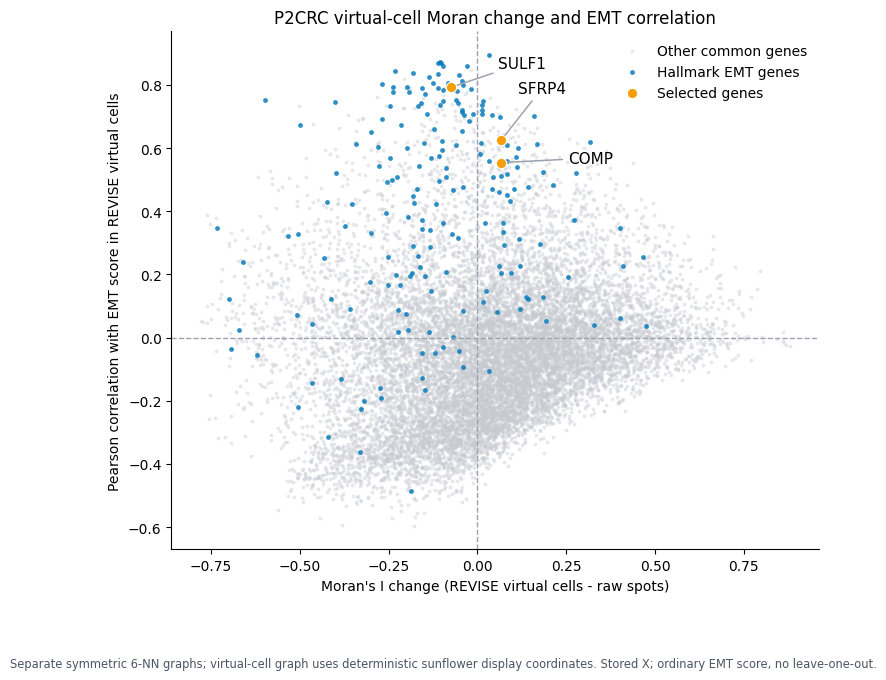

In [ ]:
finite = np.isfinite(gene_metrics["delta_moran"]) & np.isfinite(
    gene_metrics["correlation_revise_cells"]
)
is_emt = gene_metrics["in_hallmark_emt"].to_numpy()
highlight_genes = ["COMP", "SFRP4", "SULF1"]
is_highlight = gene_metrics["gene"].isin(highlight_genes).to_numpy()
annotation_offsets = {
    "SFRP4": (12, 34),
    "SULF1": (34, 14),
    "COMP": (48, 0),
}

with plt.style.context("default"):
    fig, axis = plt.subplots(figsize=(8, 7), facecolor="white")
    axis.scatter(
        gene_metrics.loc[finite & ~is_emt & ~is_highlight, "delta_moran"],
        gene_metrics.loc[
            finite & ~is_emt & ~is_highlight,
            "correlation_revise_cells",
        ],
        s=7, color="#c7cbd1", alpha=0.45, linewidths=0,
        rasterized=True, label="Other common genes"
    )
    axis.scatter(
        gene_metrics.loc[finite & is_emt & ~is_highlight, "delta_moran"],
        gene_metrics.loc[
            finite & is_emt & ~is_highlight,
            "correlation_revise_cells",
        ],
        s=12, color="#0077BB", alpha=0.82, linewidths=0,
        rasterized=True, label="Hallmark EMT genes"
    )
    first_highlight = True
    for gene in highlight_genes:
        row = gene_metrics.loc[gene_metrics["gene"] == gene].iloc[0]
        if not np.isfinite(row["delta_moran"]) or not np.isfinite(
            row["correlation_revise_cells"]
        ):
            continue
        axis.scatter(
            row["delta_moran"], row["correlation_revise_cells"],
            s=56, color="#f59e0b", edgecolor="white", linewidth=0.8,
            zorder=4, label="Selected genes" if first_highlight else None
        )
        first_highlight = False
        axis.annotate(
            gene,
            (row["delta_moran"], row["correlation_revise_cells"]),
            xytext=annotation_offsets[gene],
            textcoords="offset points",
            fontsize=11,
            arrowprops={
                "arrowstyle": "-", "color": "#9ca3af", "lw": 1.1
            },
        )
    axis.axvline(0, color="#9ca3af", linestyle="--", linewidth=1)
    axis.axhline(0, color="#9ca3af", linestyle="--", linewidth=1)
    axis.set_xlabel("Moran's I change (REVISE virtual cells - raw spots)")
    axis.set_ylabel("Pearson correlation with EMT score in REVISE virtual cells")
    axis.set_title("P2CRC virtual-cell Moran change and EMT correlation")
    axis.legend(frameon=False, loc="best")
    axis.grid(False)
    for side in ("top", "right"):
        axis.spines[side].set_visible(False)
    fig.text(
        0.5, 0.012,
        "Separate symmetric 6-NN graphs; virtual-cell graph uses deterministic "
        "sunflower display coordinates. Stored X; ordinary EMT score, no leave-one-out.",
        ha="center", fontsize=8.3, color="#4b5563"
    )
    fig.subplots_adjust(left=0.16, right=0.97, bottom=0.18, top=0.92)
    plt.show()
    plt.close(fig)